In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# BÀI TẬP 1: Khám phá dữ liệu (EDA)

**Yêu cầu**
1. Load dữ liệu.
2. Chuyển `date` thành index thời gian.
3. Vẽ đồ thị chuỗi thời gian.

**Câu hỏi cần trả lời**
- Chuỗi có xu hướng không?
- Có dấu hiệu mùa vụ không?
- Chuỗi có khả năng dừng không?

## 1.1. Đọc dữ liệu và đặt `date` làm index

In [2]:
from pathlib import Path

DATA = Path("../../data/processed/dataset1_diff.csv")   
df = pd.read_csv(DATA, parse_dates=["date"], index_col="date")[["value"]]
df = df.sort_index()
y = df["value"].astype(float)

print("5 dòng đầu tiên:")
print(df.head())
print("\nThông tin dữ liệu:")
df.info()
print("\nSố giá trị thiếu:", y.isna().sum())

5 dòng đầu tiên:
               value
date                
1991-07-01  3.526591
1991-08-01  3.180891
1991-09-01  3.252221
1991-10-01  3.611003
1991-11-01  3.565869

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
DatetimeIndex: 204 entries, 1991-07-01 to 2008-06-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   204 non-null    float64
dtypes: float64(1)
memory usage: 3.2 KB

Số giá trị thiếu: 0


## 1.2. Vẽ đồ thị chuỗi thời gian

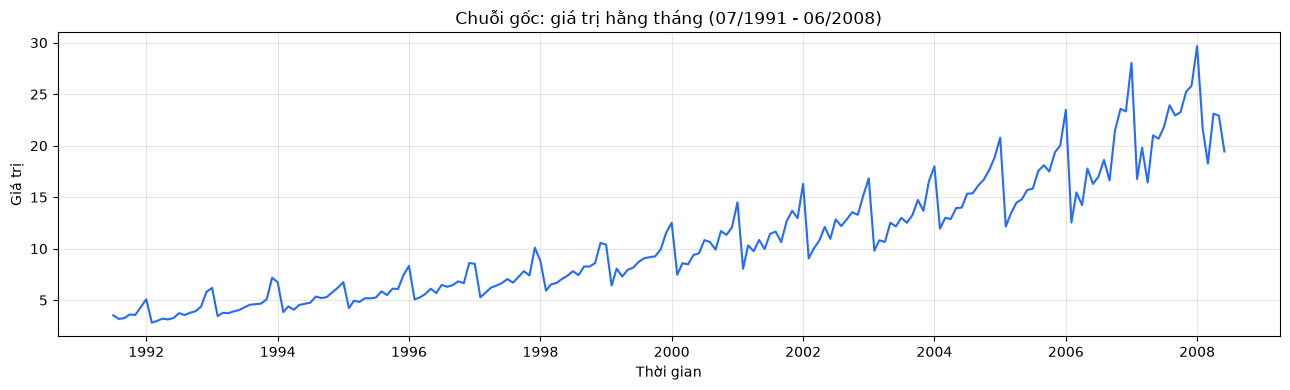

In [3]:
plt.figure(figsize=(13, 4))
plt.plot(y.index, y, color="#246BFD")
plt.title("Chuỗi gốc: giá trị hằng tháng (07/1991 - 06/2008)")
plt.xlabel("Thời gian")
plt.ylabel("Giá trị")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 1.3. Xu hướng (trung bình trượt 12 tháng, căn giữa)

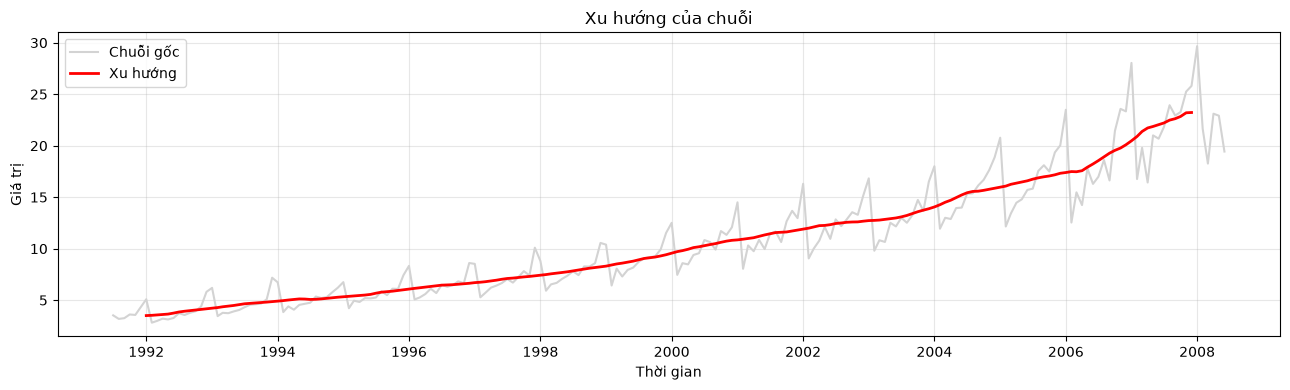

In [4]:
ma12 = y.rolling(window=12).mean()
trend = (ma12.shift(-5) + ma12.shift(-6)) / 2   # căn giữa cửa sổ 12 tháng

plt.figure(figsize=(13, 4))
plt.plot(y.index, y, color="lightgray", label="Chuỗi gốc")
plt.plot(trend.index, trend, color="red", linewidth=2, label="Xu hướng")
plt.title("Xu hướng của chuỗi")
plt.xlabel("Thời gian")
plt.ylabel("Giá trị")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 1.4. Mùa vụ (hệ số mùa vụ theo tháng)

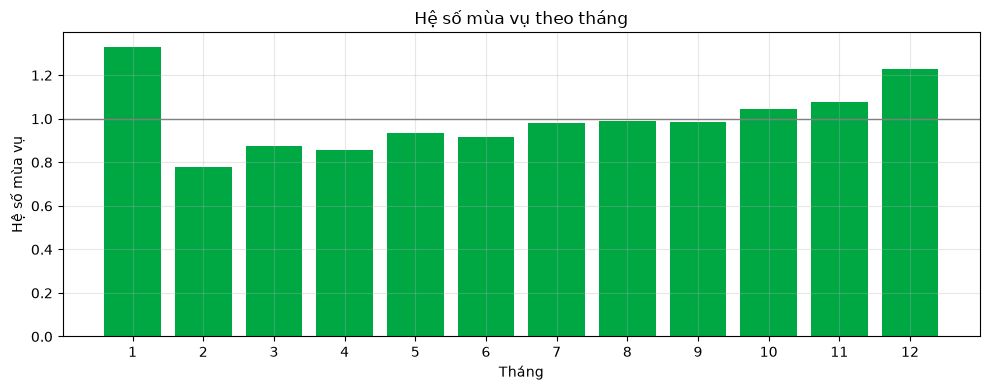

date
1     1.331
2     0.780
3     0.876
4     0.858
5     0.933
6     0.917
7     0.979
8     0.990
9     0.986
10    1.046
11    1.076
12    1.230
Name: value, dtype: float64


In [5]:
ratio = y / trend
seasonal_index = ratio.groupby(ratio.index.month).mean()
seasonal_index = seasonal_index / seasonal_index.mean()   # trung bình 12 hệ số = 1

plt.figure(figsize=(10, 4))
plt.bar(seasonal_index.index, seasonal_index.values, color="#00A844")
plt.axhline(1, color="gray", linewidth=1)
plt.xticks(range(1, 13))
plt.title("Hệ số mùa vụ theo tháng")
plt.xlabel("Tháng")
plt.ylabel("Hệ số mùa vụ")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(seasonal_index.round(3))

### Nhận xét Bài 1

- Dữ liệu gồm **204 quan sát** theo tháng, từ **07/1991** đến **06/2008**, không có giá trị thiếu. Cột `date` đã được đặt làm index thời gian.

**Câu hỏi 1. Chuỗi có xu hướng không?**
**Có.** Chuỗi tăng dần từ khoảng 3 (1991) lên gần 30 (đỉnh 29,67 vào 01/2008). Đường xu hướng tăng liên tục, từ 3,5 (01/1992) lên 23,2 (12/2007).

**Câu hỏi 2. Có dấu hiệu mùa vụ không?**
**Có.** Mẫu hình lặp lại mỗi 12 tháng. Tháng 1 cao nhất (hệ số 1,331), kế đến tháng 12 (1,230); tháng 2 thấp nhất (0,780).

**Câu hỏi 3. Chuỗi có khả năng dừng không?**
**Nhiều khả năng không dừng.** Trung bình tăng theo thời gian và biên độ dao động to dần (chênh lệch trong năm 1992 khoảng 3 đơn vị, năm 2007 khoảng 11,6 đơn vị). Sẽ kiểm định chính thức bằng ADF ở Bài 2.

# BÀI TẬP 2: Kiểm định ADF trên chuỗi gốc

**Yêu cầu**
- Thực hiện kiểm định ADF cho chuỗi gốc: ADF statistic, p-value, kết luận dừng / không dừng.

**Câu hỏi cần trả lời**
- H₀ của ADF là gì?
- p-value cho biết điều gì?
- Chuỗi có dừng không?

## 2.1. Giả thuyết và quy tắc quyết định
- **H₀:** chuỗi có nghiệm đơn vị (**không dừng**).
- **H₁:** chuỗi dừng.
- **Quy tắc:** p-value ≤ 0,05 thì bác bỏ H₀, kết luận chuỗi dừng. p-value > 0,05 thì chưa đủ bằng chứng bác bỏ H₀, chuỗi không dừng.
- **Cách đọc thứ hai:** nếu ADF statistic **nhỏ hơn** giá trị tới hạn ở mức 5% thì chuỗi dừng.

## 2.2. Quan sát trực quan trước khi kiểm định: trung bình trượt và độ lệch chuẩn trượt
Chuỗi dừng cần trung bình và phương sai **không đổi** theo thời gian. Ta vẽ hai đại lượng này trên cửa sổ 12 tháng để quan sát.

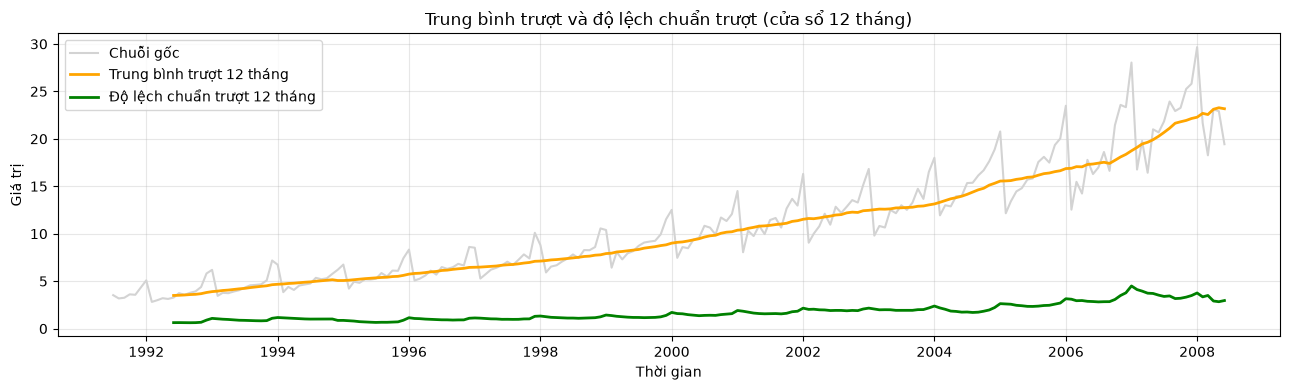

In [6]:
roll_mean = y.rolling(window=12).mean()
roll_std = y.rolling(window=12).std()

plt.figure(figsize=(13, 4))
plt.plot(y.index, y, color="lightgray", label="Chuỗi gốc")
plt.plot(roll_mean.index, roll_mean, color="orange", linewidth=2, label="Trung bình trượt 12 tháng")
plt.plot(roll_std.index, roll_std, color="green", linewidth=2, label="Độ lệch chuẩn trượt 12 tháng")
plt.title("Trung bình trượt và độ lệch chuẩn trượt (cửa sổ 12 tháng)")
plt.xlabel("Thời gian")
plt.ylabel("Giá trị")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét:** Trung bình trượt tăng từ khoảng 3,5 (06/1992) lên 23,2 (06/2008), gấp khoảng 6,6 lần. Độ lệch chuẩn trượt cũng tăng từ 0,63 lên 2,96, gấp khoảng 4,7 lần. Vậy **cả trung bình lẫn phương sai đều thay đổi theo thời gian**, chuỗi chưa thỏa điều kiện dừng.

## 2.3. Kiểm định ADF trên chuỗi gốc

In [7]:
stat, pval, lags, nobs, crit, _ = adfuller(y, regression="c", autolag="AIC")

print("ADF statistic :", round(stat, 4))
print("p-value       :", round(pval, 4))
print("Số lag dùng   :", lags, "| Số quan sát:", nobs)
for muc, gt in crit.items():
    print(f"Giá trị tới hạn {muc}: {gt:.4f}")

print("\np-value <= 0.05 ?         ", pval <= 0.05)
print("Statistic < critical 5% ? ", stat < crit["5%"])

ADF statistic : 3.1452
p-value       : 1.0
Số lag dùng   : 15 | Số quan sát: 188
Giá trị tới hạn 1%: -3.4656
Giá trị tới hạn 5%: -2.8770
Giá trị tới hạn 10%: -2.5750

p-value <= 0.05 ?          False
Statistic < critical 5% ?  False


## 2.4. ADF statistic so với các giá trị tới hạn
Chuỗi dừng khi ADF statistic **nằm bên trái** (nhỏ hơn) giá trị tới hạn.

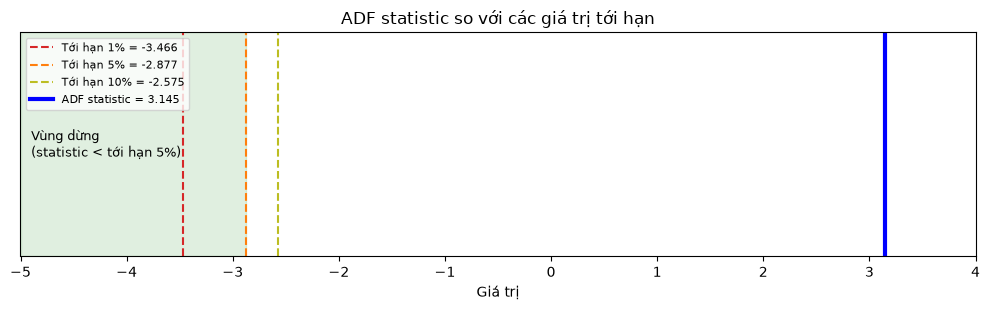

In [8]:
plt.figure(figsize=(10, 3.2))
for muc, mau in zip(["1%", "5%", "10%"], ["#d62728", "#ff7f0e", "#bcbd22"]):
    plt.axvline(crit[muc], color=mau, linestyle="--", label=f"Tới hạn {muc} = {crit[muc]:.3f}")
plt.axvline(stat, color="blue", linewidth=3, label=f"ADF statistic = {stat:.3f}")
plt.axvspan(-5, crit["5%"], color="green", alpha=0.12)
plt.text(-4.9, 0.5, "Vùng dừng\n(statistic < tới hạn 5%)", va="center", fontsize=9)
plt.xlim(-5, 4)
plt.yticks([])
plt.title("ADF statistic so với các giá trị tới hạn")
plt.xlabel("Giá trị")
plt.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Nhận xét:** ADF statistic (3,145) nằm **rất xa bên phải** cả ba giá trị tới hạn (−3,466; −2,877; −2,575) và nằm ngoài vùng dừng, nên không bác bỏ được H₀.

## 2.5. So sánh nửa đầu và nửa sau của chuỗi

In [9]:
nua = len(y) // 2
bang = pd.DataFrame({
    "Giai đoạn": [f"{y.index[0]:%m/%Y} - {y.index[nua-1]:%m/%Y}", f"{y.index[nua]:%m/%Y} - {y.index[-1]:%m/%Y}"],
    "Trung bình": [y.iloc[:nua].mean(), y.iloc[nua:].mean()],
    "Độ lệch chuẩn": [y.iloc[:nua].std(), y.iloc[nua:].std()],
}, index=["Nửa đầu", "Nửa sau"]).round(2)
display(bang)

,Giai đoạn,Trung bình,Độ lệch chuẩn
Nửa đầu,07/1991 - 12/1999,6.01,1.96
Nửa sau,01/2000 - 06/2008,15.38,4.80


**Nhận xét:** Nửa sau có trung bình (15,38) gấp khoảng 2,6 lần nửa đầu (6,01) và độ lệch chuẩn (4,80) gấp khoảng 2,4 lần (1,96). Hai nửa của chuỗi có đặc trưng thống kê khác nhau rõ rệt, trái với tính chất của chuỗi dừng.

### Nhận xét Bài 2

**Kết quả ADF:**

| Chỉ số | Giá trị |
|---|---|
| ADF statistic | 3,1452 |
| p-value | 1,0000 |
| Số lag dùng | 15 |
| Giá trị tới hạn 1% / 5% / 10% | −3,4656 / −2,8770 / −2,5750 |

**Câu hỏi 1. H₀ của ADF là gì?**
H₀: chuỗi **có nghiệm đơn vị**, tức **không dừng**. H₁: chuỗi dừng.

**Câu hỏi 2. p-value cho biết điều gì?**
p-value là mức bằng chứng chống lại H₀: p-value càng nhỏ thì càng có cơ sở bác bỏ H₀. Với ngưỡng 0,05: p-value ≤ 0,05 thì bác bỏ H₀ (chuỗi dừng), p-value > 0,05 thì chưa đủ bằng chứng bác bỏ H₀ (chuỗi không dừng).

**Câu hỏi 3. Chuỗi có dừng không?**
**Không dừng.** p-value = 1,0 lớn hơn 0,05 rất nhiều, và ADF statistic (3,1452) lớn hơn giá trị tới hạn 5% (−2,8770), nên không bác bỏ được H₀. Kết quả khớp với quan sát trực quan: trung bình trượt tăng gấp khoảng 6,6 lần, độ lệch chuẩn trượt gấp khoảng 4,7 lần, và hai nửa của chuỗi có trung bình khác nhau rõ rệt (6,01 so với 15,38). Vì vậy cần **sai phân** ở Bài 3.

# BÀI TẬP 3: Sai phân và kiểm định lại

**Yêu cầu**
1. Sai phân bậc 1.
2. Vẽ lại đồ thị chuỗi sau sai phân.
3. Kiểm định ADF lần 2.

**Câu hỏi cần trả lời**
- Sau sai phân, chuỗi đã dừng chưa?
- Giá trị d trong ARIMA là bao nhiêu?

## 3.1. Sai phân bậc 1
Công thức: y'ₜ = yₜ − yₜ₋₁. Tháng đầu tiên không có tháng trước để trừ nên bị rỗng (NaN), ta bỏ bằng `dropna()`.

In [10]:
y_diff1 = y.diff().dropna()

print("Số quan sát:", len(y), "→", len(y_diff1))
print(y_diff1.head(3))

Số quan sát: 204 → 203
date
1991-08-01   -0.345700
1991-09-01    0.071330
1991-10-01    0.358782
Name: value, dtype: float64


## 3.2. Đồ thị chuỗi sau sai phân bậc 1

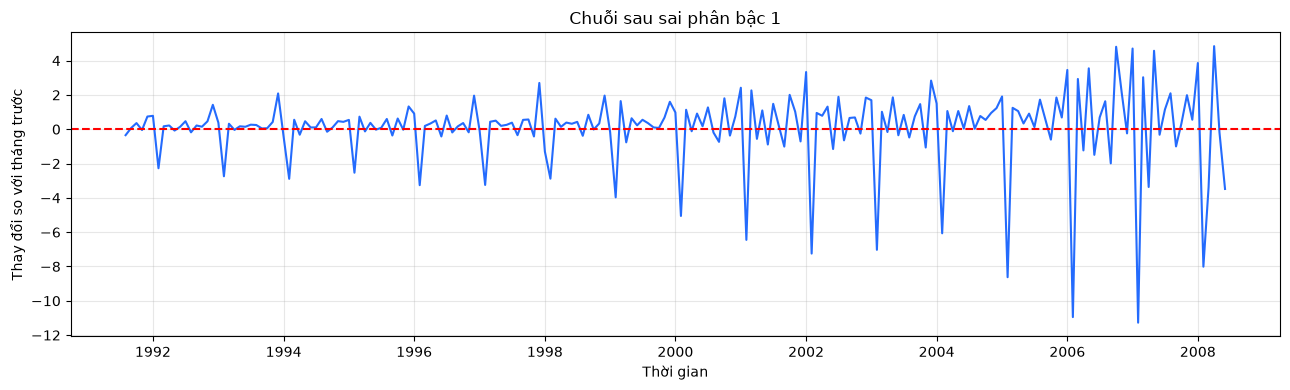

In [11]:
plt.figure(figsize=(13, 4))
plt.plot(y_diff1.index, y_diff1, color="#246BFD")
plt.axhline(0, color="red", linestyle="--")
plt.title("Chuỗi sau sai phân bậc 1")
plt.xlabel("Thời gian")
plt.ylabel("Thay đổi so với tháng trước")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét:** Xu hướng đi lên đã mất, chuỗi dao động quanh mức 0 (đường đỏ). Tuy vậy biên độ dao động vẫn to dần về cuối chuỗi và các đỉnh nhọn vẫn lặp lại mỗi năm (mùa vụ).

## 3.3. Kiểm định ADF lần 2 (chuỗi sau sai phân bậc 1)
- **H₀:** chuỗi có nghiệm đơn vị (không dừng).
- **H₁:** chuỗi dừng.
- Quy tắc: p-value ≤ 0,05 hoặc ADF statistic < giá trị tới hạn 5% thì chuỗi dừng.

In [12]:
stat1, p1, lags1, nobs1, crit1, _ = adfuller(y_diff1, regression="c", autolag="AIC")

print("ADF statistic :", round(stat1, 4))
print("p-value       :", round(p1, 4))
print("Số lag dùng   :", lags1, "| Số quan sát:", nobs1)
for muc, gt in crit1.items():
    print(f"Giá trị tới hạn {muc}: {gt:.4f}")

print("\np-value <= 0.05 ?         ", p1 <= 0.05)
print("Statistic < critical 5% ? ", stat1 < crit1["5%"])

ADF statistic : -2.4952
p-value       : 0.1167
Số lag dùng   : 15 | Số quan sát: 187
Giá trị tới hạn 1%: -3.4658
Giá trị tới hạn 5%: -2.8771
Giá trị tới hạn 10%: -2.5751

p-value <= 0.05 ?          False
Statistic < critical 5% ?  False


**Nhận xét:** ADF statistic = −2,4952 (lớn hơn tới hạn 5% là −2,8771) và p-value = 0,1167 > 0,05, nên theo ngưỡng 0,05 chuỗi sau sai phân bậc 1 **chưa dừng**. Tuy nhiên, so với chuỗi gốc (statistic = 3,1452; p-value = 1,0), kết quả đã tiến gần ngưỡng dừng rất nhiều.

## 3.4. Thử sai phân bậc 2 và so sánh
Ta thử bậc 2, đồng thời kiểm tra dấu hiệu **sai phân quá mức** (độ lệch chuẩn tăng, ACF lag 1 xuống rất âm).

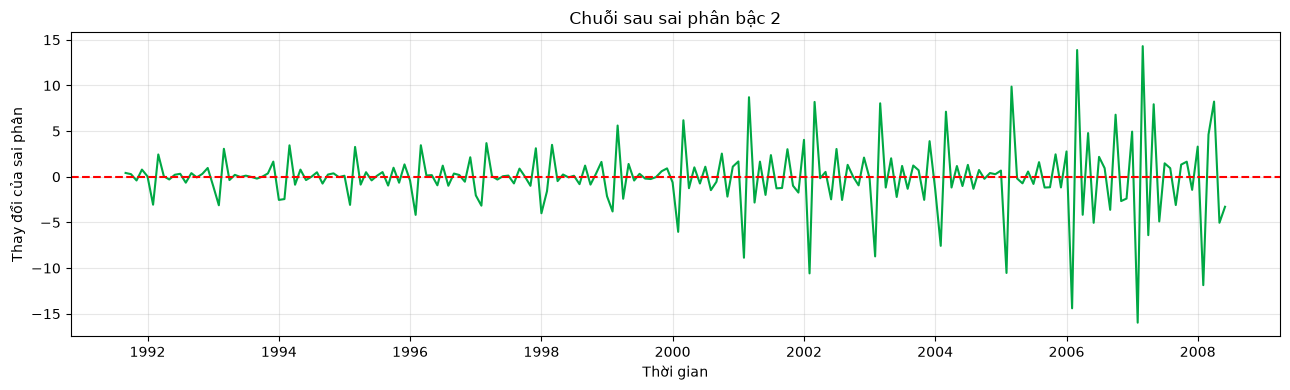

,ADF statistic,Tới hạn 5%,p-value,Dừng theo ADF?,Độ lệch chuẩn,ACF lag 1
Chuỗi,,,,,,
Gốc,3.1452,-2.8770,1,Chưa,5.957,0.921
Sai phân bậc 1 (d = 1),-2.4952,-2.8771,0.1167,Chưa,2.242,-0.365
Sai phân bậc 2 (d = 2),-10.2923,-2.8771,3.544e-18,Có,3.705,-0.635


In [13]:
y_diff2 = y_diff1.diff().dropna()

plt.figure(figsize=(13, 4))
plt.plot(y_diff2.index, y_diff2, color="#00A844")
plt.axhline(0, color="red", linestyle="--")
plt.title("Chuỗi sau sai phân bậc 2")
plt.xlabel("Thời gian")
plt.ylabel("Thay đổi của sai phân")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

def tom_tat(x, ten):
    stat, pval, lags, nobs, crit, _ = adfuller(x, regression="c", autolag="AIC")
    return {"Chuỗi": ten, "ADF statistic": round(stat, 4), "Tới hạn 5%": round(crit["5%"], 4),
            "p-value": f"{pval:.4g}", "Dừng theo ADF?": "Có" if pval <= 0.05 else "Chưa",
            "Độ lệch chuẩn": round(x.std(), 3), "ACF lag 1": round(acf(x, nlags=1)[1], 3)}

bang = pd.DataFrame([tom_tat(y, "Gốc"),
                     tom_tat(y_diff1, "Sai phân bậc 1 (d = 1)"),
                     tom_tat(y_diff2, "Sai phân bậc 2 (d = 2)")]).set_index("Chuỗi")
display(bang)

**Nhận xét:** Sai phân bậc 2 làm ADF vượt ngưỡng dừng (p ≈ 3,5e-18), nhưng đồng thời độ lệch chuẩn tăng từ 2,242 lên 3,705 và ACF lag 1 giảm xuống −0,635. Đây là dấu hiệu của **sai phân quá mức**.

## 3.5. Vì sao sai phân bậc 1 chưa dừng? Tìm nguyên nhân bằng ACF
Nếu phần chưa dừng còn lại là **mùa vụ**, ACF của chuỗi sau sai phân sẽ có các đỉnh cao tại lag 12, 24, 36. Ta so sánh ACF sau sai phân bậc 1 và bậc 2.

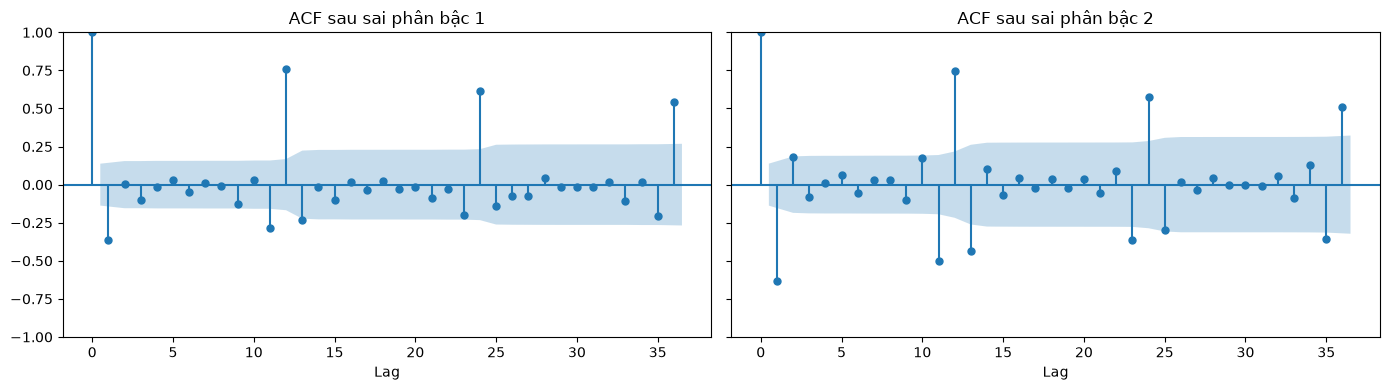

            Bậc 1  Bậc 2
ACF lag 12  0.757  0.746
ACF lag 24  0.615  0.574
ACF lag 36  0.539  0.507


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_acf(y_diff1, lags=36, ax=axes[0], title="ACF sau sai phân bậc 1")
plot_acf(y_diff2, lags=36, ax=axes[1], title="ACF sau sai phân bậc 2")
for ax in axes:
    ax.set_xlabel("Lag")
plt.tight_layout()
plt.show()

a1, a2 = acf(y_diff1, nlags=36), acf(y_diff2, nlags=36)
print(pd.DataFrame({"Bậc 1": [a1[12], a1[24], a1[36]],
                    "Bậc 2": [a2[12], a2[24], a2[36]]},
                   index=["ACF lag 12", "ACF lag 24", "ACF lag 36"]).round(3))

**Nhận xét:** Sau sai phân bậc 1, ACF có các đỉnh cao tại lag 12, 24, 36 (0,757; 0,615; 0,539): đây là **mùa vụ chu kỳ 12 tháng**. Sau sai phân bậc 2, các đỉnh này gần như không đổi (0,746; 0,574; 0,507). Tức **tăng d không loại bỏ được mùa vụ**; nó chỉ làm tăng nhiễu (ACF lag 1 xuống −0,635).

## 3.6. Xử lý đúng nguyên nhân: sai phân mùa vụ (D = 1, s = 12)
Ta so sánh: chỉ sai phân mùa vụ, và sai phân bậc 1 kết hợp sai phân mùa vụ.

In [15]:
y_D1 = y.diff(12).dropna()                 # chỉ sai phân mùa vụ
y_d1D1 = y.diff().diff(12).dropna()        # sai phân bậc 1 + sai phân mùa vụ

bang_mv = pd.DataFrame([tom_tat(y_D1, "Chỉ sai phân mùa vụ (D = 1)"),
                        tom_tat(y_d1D1, "Bậc 1 + mùa vụ (d = 1, D = 1)")]).set_index("Chuỗi")
display(bang_mv)
print("ACF lag 12 sau (d = 1, D = 1):", round(acf(y_d1D1, nlags=12)[12], 3))

,ADF statistic,Tới hạn 5%,p-value,Dừng theo ADF?,Độ lệch chuẩn,ACF lag 1
Chuỗi,,,,,,
Chỉ sai phân mùa vụ (D = 1),-2.0927,-2.8779,0.2475,Chưa,1.219,0.373
"Bậc 1 + mùa vụ (d = 1, D = 1)",-4.7834,-2.8779,5.85e-05,Có,1.356,-0.574


ACF lag 12 sau (d = 1, D = 1): -0.172


**Nhận xét:** Chỉ sai phân mùa vụ chưa đủ (p = 0,2475, còn xu hướng). Nhưng **sai phân bậc 1 kết hợp sai phân mùa vụ** cho p = 5,85e-05 (dừng) và ACF lag 12 giảm xuống −0,172. Như vậy chỉ cần **d = 1** nếu mùa vụ được xử lý đúng chỗ; d = 2 là không cần thiết.

## 3.7. Độ ổn định của kết quả ADF trên sai phân bậc 1
ADF phụ thuộc số lag. Ta thay đổi số lag tối đa để xem kết luận "chưa dừng" của bậc 1 có vững không.

In [16]:
ket_qua = {m: adfuller(y_diff1, maxlag=m, autolag=None)[1] for m in range(0, 16)}
bang_lag = pd.DataFrame({"Số lag": list(ket_qua.keys()),
                         "p-value": [f"{p:.4g}" for p in ket_qua.values()],
                         "Dừng (p ≤ 0,05)?": ["Có" if p <= 0.05 else "Chưa" for p in ket_qua.values()]})
display(bang_lag.set_index("Số lag"))

,p-value,"Dừng (p ≤ 0,05)?"
Số lag,,
0,0,Có
1,3.493e-25,Có
2,2.617e-21,Có
3,1.557e-18,Có
4,1.065e-14,Có
5,1.976e-13,Có
6,2.629e-12,Có
7,3.207e-11,Có
8,3.049e-14,Có


**Nhận xét:** Với số lag tối đa từ 0 đến 14, ADF trên sai phân bậc 1 đều cho p < 0,05; chỉ riêng cấu hình 15 lag (do AIC tự chọn) cho p = 0,1167. Kết luận "bậc 1 chưa dừng" vì vậy **không vững**. Lưu ý: ít lag thì phần dư của phép kiểm định còn tự tương quan mùa vụ nên các p-value nhỏ ấy cũng không hoàn toàn tin cậy; ta chỉ dùng bảng này để chỉ ra tính mong manh của kết quả, không để khẳng định bậc 1 chắc chắn dừng.

## 3.8. Kiểm chứng bằng dự báo (xem trước Bài 5)
Chia 80% train, 20% test theo thứ tự thời gian. So sánh các mô hình ARIMA với d = 1 và d = 2 trên cùng tập test.

In [17]:
yt = y.asfreq("MS")
n_tr = int(len(yt) * 0.8)
train, test = yt.iloc[:n_tr], yt.iloc[n_tr:]

def danh_gia(order, seasonal=None):
    if seasonal is None:
        fit = ARIMA(train, order=order).fit()
    else:
        fit = SARIMAX(train, order=order, seasonal_order=seasonal).fit(disp=False)
    du_bao = fit.forecast(len(test))
    mae = np.abs(test - du_bao).mean()
    rmse = np.sqrt(((test - du_bao) ** 2).mean())
    mape = (np.abs((test - du_bao) / test)).mean() * 100
    return round(mae, 2), round(rmse, 2), round(mape, 1)

mo_hinh = [("ARIMA(0,1,1)", (0, 1, 1)), ("ARIMA(1,1,1)", (1, 1, 1)), ("ARIMA(2,1,1)", (2, 1, 1)),
           ("ARIMA(0,2,1)", (0, 2, 1)), ("ARIMA(1,2,1)", (1, 2, 1)), ("ARIMA(2,2,1)", (2, 2, 1))]
hang = [(ten,) + danh_gia(o) for ten, o in mo_hinh]
hang.append(("SARIMA(1,1,1)(1,1,1,12)",) + danh_gia((1, 1, 1), (1, 1, 1, 12)))
display(pd.DataFrame(hang, columns=["Mô hình", "MAE", "RMSE", "MAPE (%)"]).set_index("Mô hình"))

,MAE,RMSE,MAPE (%)
Mô hình,,,
"ARIMA(0,1,1)",3.46,4.15,18.4
"ARIMA(1,1,1)",3.67,4.62,18.0
"ARIMA(2,1,1)",3.67,4.63,18.1
"ARIMA(0,2,1)",4.18,4.88,24.9
"ARIMA(1,2,1)",3.89,4.56,23.1
"ARIMA(2,2,1)",3.64,4.30,21.5
"SARIMA(1,1,1)(1,1,1,12)",1.56,2.00,9.1


**Nhận xét:** Theo MAPE, mọi mô hình d = 1 (18,0% đến 18,4%) đều tốt hơn mọi mô hình d = 2 (21,5% đến 24,9%). Theo MAE và RMSE hai nhóm xen kẽ, nhưng so mô hình tốt nhất của mỗi nhóm thì ARIMA(0,1,1) thắng ARIMA(2,2,1) ở cả ba chỉ số (MAE 3,46 so với 3,64; RMSE 4,15 so với 4,30; MAPE 18,4% so với 21,5%). Khi xử lý mùa vụ (SARIMA), sai số giảm khoảng một nửa (MAPE 9,1%). Đây mới là cải thiện lớn, không phải tăng d. (Kết quả chỉ trên một lần chia train/test, mang tính tham khảo.)

### Nhận xét Bài 3

| Chuỗi | ADF statistic | p-value | Dừng theo ADF? | Độ lệch chuẩn | ACF lag 1 | ACF lag 12 |
|---|---|---|---|---|---|---|
| Gốc | 3,1452 | 1,0 | Chưa | 5,957 | 0,921 | - |
| Sai phân bậc 1 (d = 1) | −2,4952 | 0,1167 | Chưa (sát ngưỡng) | 2,242 | −0,365 | 0,757 |
| Sai phân bậc 2 (d = 2) | −10,2923 | 3,5e-18 | Có | 3,705 | −0,635 | 0,746 |
| Bậc 1 + mùa vụ (d = 1, D = 1) | −4,7834 | 5,85e-05 | Có | 1,356 | −0,574 | −0,172 |

**Câu hỏi 1. Sau sai phân, chuỗi đã dừng chưa?**
Sau sai phân bậc 1, xu hướng đã mất và chuỗi dao động quanh 0. ADF với 15 lag (AIC) cho p = 0,1167 > 0,05 nên **chưa dừng theo kiểm định mặc định**, nhưng kết quả này mong manh: với số lag tối đa từ 0 đến 14, p đều nhỏ hơn 0,05. Nguyên nhân phần chưa ổn định còn lại là **mùa vụ chu kỳ 12 tháng**: ACF có đỉnh tại lag 12, 24, 36 (0,757; 0,615; 0,539). Khi sai phân mùa vụ được thêm vào (d = 1, D = 1), chuỗi dừng rõ ràng (p = 5,85e-05).

**Câu hỏi 2. Giá trị d trong ARIMA là bao nhiêu?**
**d = 1.** Căn cứ:
1. **Sai phân bậc 2 không giải quyết nguyên nhân thật.** ACF lag 12 gần như không đổi (0,757 → 0,746), trong khi nó gây sai phân quá mức: độ lệch chuẩn tăng từ 2,242 lên 3,705 và ACF lag 1 giảm xuống −0,635.
2. **Xử lý đúng nguyên nhân thì d = 1 là đủ.** Với d = 1 và D = 1, ADF cho p = 5,85e-05 và ACF lag 12 chỉ còn −0,172.
3. **Dự báo ủng hộ d = 1.** MAPE của các mô hình d = 1 (18,0% đến 18,4%) tốt hơn d = 2 (21,5% đến 24,9%); mô hình tốt nhất của d = 1 thắng mô hình tốt nhất của d = 2 ở cả MAE, RMSE, MAPE.

**Giới hạn cần nêu rõ:** ADF bậc 1 với cài đặt mặc định chưa đạt ngưỡng 0,05, và kết quả dự báo chỉ trên một lần chia dữ liệu. Phần mùa vụ còn lại chưa được ARIMA xử lý (phần dư chưa phải nhiễu trắng) và sẽ được giải quyết bằng SARIMA (D = 1, s = 12) ở phần nâng cao, nơi sai số giảm gần một nửa (MAPE 9,1%).

# BÀI TẬP 4: Phân tích ACF và PACF

**Yêu cầu**
1. Vẽ ACF và PACF của chuỗi đã dừng.
2. Đề xuất (p, d, q).

**Câu hỏi cần trả lời**
- ACF cắt cụt ở lag nào?
- PACF cắt cụt ở lag nào?
- Gợi ý mô hình ARIMA(p, d, q)?

## 4.1. Vẽ ACF và PACF của chuỗi sau sai phân bậc 1 (d = 1)
Vùng xanh nhạt là khoảng tin cậy 95%: lag nào có cột vượt ra ngoài vùng này là có ý nghĩa thống kê.

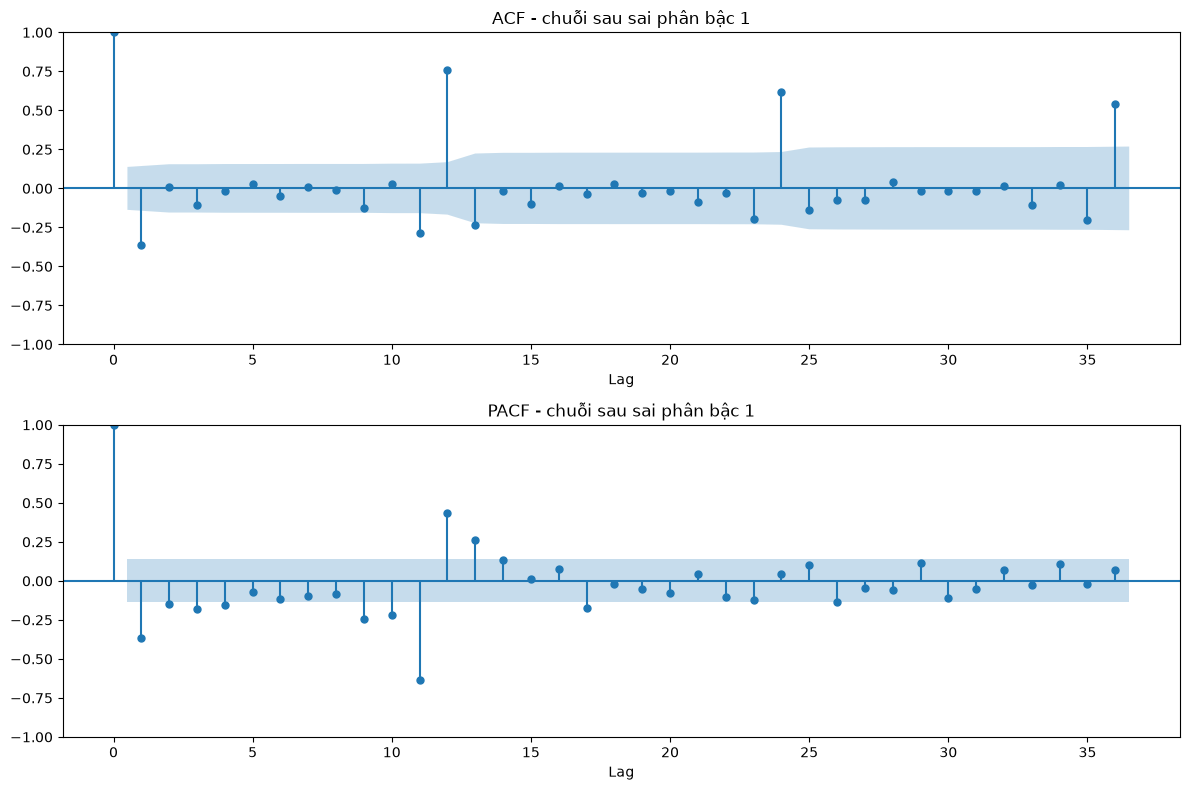

In [18]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(y_diff1, lags=36, ax=ax[0], title="ACF - chuỗi sau sai phân bậc 1")
plot_pacf(y_diff1, lags=36, ax=ax[1], method="ywm", title="PACF - chuỗi sau sai phân bậc 1")
for a in ax:
    a.set_xlabel("Lag")
plt.tight_layout()
plt.show()

## 4.2. Bảng số ACF và PACF
Ngưỡng tin cậy 95% là ±1,96/√n. Cột "vượt dải" cho biết lag có ý nghĩa thống kê hay không.

In [19]:
n = len(y_diff1)
ci = 1.96 / np.sqrt(n)
gia_tri_acf = acf(y_diff1, nlags=36)
gia_tri_pacf = pacf(y_diff1, nlags=36, method="ywm")

bang_acf = pd.DataFrame({"ACF": gia_tri_acf, "PACF": gia_tri_pacf})
bang_acf["ACF vượt dải"] = bang_acf["ACF"].abs() > ci
bang_acf["PACF vượt dải"] = bang_acf["PACF"].abs() > ci
bang_acf.index.name = "Lag"

print(f"Ngưỡng tin cậy: ±{ci:.3f}")
display(bang_acf.iloc[1:].round(3))

Ngưỡng tin cậy: ±0.138


,ACF,PACF,ACF vượt dải,PACF vượt dải
Lag,,,,
1,-0.365,-0.365,True,True
2,0.006,-0.147,False,True
3,-0.103,-0.182,False,True
4,-0.017,-0.156,False,True
5,0.031,-0.074,False,False
6,-0.049,-0.116,False,False
7,0.009,-0.096,False,False
8,-0.010,-0.084,False,False
9,-0.125,-0.243,False,True


### Nhận xét Bài 4

Ngưỡng tin cậy 95% là ±0,138 (n = 203). Các lag vượt ngưỡng:

| | Lag vượt ngưỡng | Giá trị chính |
|---|---|---|
| **ACF** | 1, 11, 12, 13, 23, 24, 25, 35, 36 | lag 1 = −0,365; lag 12 = 0,757; lag 24 = 0,615; lag 36 = 0,539 |
| **PACF** | 1, 2, 3, 4, 9, 10, 11, 12, 13, 17 | lag 1 = −0,365; lag 2 = −0,147; lag 3 = −0,182; lag 4 = −0,156; lag 11 = −0,634; lag 12 = 0,433 |

**Câu hỏi 1. ACF cắt cụt ở lag nào?**
Với phần không mùa vụ, ACF vượt ngưỡng rõ ở **lag 1** (−0,365), rồi **lag 2 đến 10 đều nằm trong ngưỡng**. Vậy ACF cắt cụt sau lag 1, gợi ý **q = 1**. Các lag 11 đến 13, 23 đến 25, 35, 36 vượt ngưỡng theo chu kỳ 12 tháng (đặc biệt lag 12, 24, 36 giảm dần rất chậm: 0,757; 0,615; 0,539) là **dấu hiệu mùa vụ**, không dùng để chọn q của ARIMA thường.

**Câu hỏi 2. PACF cắt cụt ở lag nào?**
PACF **không cắt cụt gọn**: lag 1 đến 4 đều vượt ngưỡng và cùng âm (−0,365; −0,147; −0,182; −0,156), kéo dài thay vì dừng đột ngột. Các cột nổi ở lag 9 đến 13 (lag 11 = −0,634; lag 12 = 0,433) thuộc ảnh hưởng mùa vụ. Vì PACF không cắt cụt tại một lag nhỏ, chuỗi không phải AR thuần, nên chọn **p = 0** làm mô hình chính.

**Câu hỏi 3. Gợi ý mô hình ARIMA(p, d, q)?**
- **Mô hình chính: ARIMA(0, 1, 1)**, vì ACF cắt cụt sau lag 1 và PACF giảm dần (đặc trưng của MA(1)); d = 1 theo Bài 3.
- **Mô hình so sánh: ARIMA(1, 1, 1) và ARIMA(2, 1, 1)** (trùng ví dụ của đề), thêm thành phần AR để bắt các lag 2 đến 4 của PACF.
- Việc chọn p giữa 0, 1, 2 là gợi ý từ biểu đồ; sẽ so sánh bằng AIC/BIC và sai số dự báo ở Bài 5.

**Lưu ý:** ACF và PACF đều cho thấy mùa vụ chu kỳ 12 tháng vẫn còn trong chuỗi sau sai phân bậc 1. ARIMA(p, 1, q) không xử lý được phần này, nên ở phần nâng cao sẽ dùng SARIMA(p, d, q)(P, D, Q, 12).

# BÀI TẬP 5: Thiết lập ARIMA, dự đoán và đánh giá

**Yêu cầu**
1. Chia dữ liệu: train 80%, test 20%, giữ nguyên thứ tự thời gian (không shuffle).
2. Thiết lập mô hình ARIMA dựa trên ACF/PACF, fit trên tập train, ghi lại AIC và BIC.
3. Chẩn đoán phần dư: vẽ residuals theo thời gian, ACF của residuals; kiểm tra mean ≈ 0 và tự tương quan.
4. Dự đoán trên tập test, vẽ Train, Test (thực tế), Forecast.
5. Đánh giá bằng MAE, RMSE, MAPE.

## 5.1. Chia dữ liệu train/test (80% / 20%)
Chuỗi thời gian có tính phụ thuộc thời gian, nên chia theo **thứ tự**: phần đầu làm train, phần cuối làm test. Không xáo trộn dữ liệu.

Train: 163 quan sát | 07/1991 - 01/2005
Test : 41 quan sát | 02/2005 - 06/2008


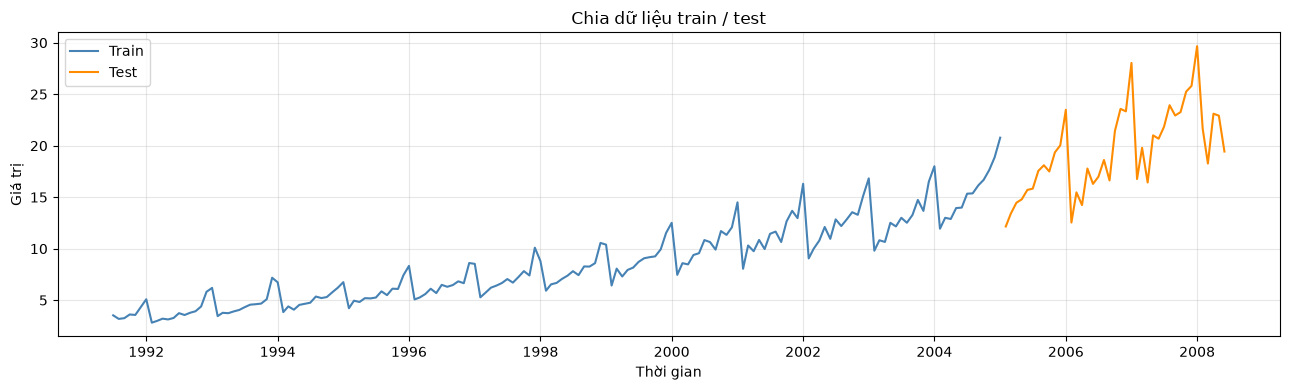

In [20]:
yt = y.asfreq("MS")
n_train = int(len(yt) * 0.8)
train, test = yt.iloc[:n_train], yt.iloc[n_train:]

print("Train:", len(train), "quan sát |", train.index[0].strftime("%m/%Y"), "-", train.index[-1].strftime("%m/%Y"))
print("Test :", len(test), "quan sát |", test.index[0].strftime("%m/%Y"), "-", test.index[-1].strftime("%m/%Y"))

plt.figure(figsize=(13, 4))
plt.plot(train, label="Train", color="steelblue")
plt.plot(test, label="Test", color="darkorange")
plt.title("Chia dữ liệu train / test")
plt.xlabel("Thời gian")
plt.ylabel("Giá trị")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét:** 163 quan sát đầu (07/1991 đến 01/2005) làm tập train, 41 quan sát cuối (02/2005 đến 06/2008) làm tập test. Tập test nằm hoàn toàn **sau** tập train theo thời gian, đúng như khi dự báo thực tế.

## 5.2. Thiết lập và fit mô hình ARIMA
Từ Bài 3 chọn **d = 1**. Từ Bài 4 (ACF cắt sau lag 1, PACF giảm dần) chọn mô hình chính **ARIMA(0,1,1)**, và thêm **ARIMA(1,1,1)**, **ARIMA(2,1,1)** để so sánh. Cả ba fit trên tập train.

In [21]:
from statsmodels.tsa.arima.model import ARIMA

orders = [(0, 1, 1), (1, 1, 1), (2, 1, 1)]
models = {}
rows = []
for o in orders:
    m = ARIMA(train, order=o).fit()
    models[o] = m
    rows.append({"Mô hình": f"ARIMA{o}", "AIC": round(m.aic, 2), "BIC": round(m.bic, 2),
                 "Hội tụ": m.mle_retvals.get("converged")})

pd.DataFrame(rows).set_index("Mô hình")

,AIC,BIC,Hội tụ
Mô hình,,,
"ARIMA(0, 1, 1)",587.92,594.09,True
"ARIMA(1, 1, 1)",582.47,591.73,True
"ARIMA(2, 1, 1)",584.46,596.81,True


**Nhận xét:** Cả ba mô hình đều hội tụ. ARIMA(1,1,1) có AIC và BIC thấp nhất (582,47 và 591,73), nên là mô hình tốt nhất theo tiêu chí thông tin. ARIMA(2,1,1) thêm một tham số nhưng AIC/BIC lại tăng, nghĩa là tham số thêm không cải thiện đủ. ARIMA(0,1,1) đơn giản nhất nhưng AIC cao hơn khoảng 5 đơn vị. Ba mô hình cùng d = 1 nên so sánh AIC/BIC là hợp lệ.

## 5.3. Chẩn đoán phần dư (residuals)
Nếu mô hình đã nắm hết cấu trúc của chuỗi, phần dư phải giống **nhiễu trắng**: mean ≈ 0 và không còn tự tương quan. Kiểm tra bằng đồ thị, ACF của phần dư và kiểm định Ljung-Box (H0: phần dư là nhiễu trắng). Ngoài lag 10, kiểm thêm lag 12 và 24 vì chuỗi có mùa vụ s = 12.

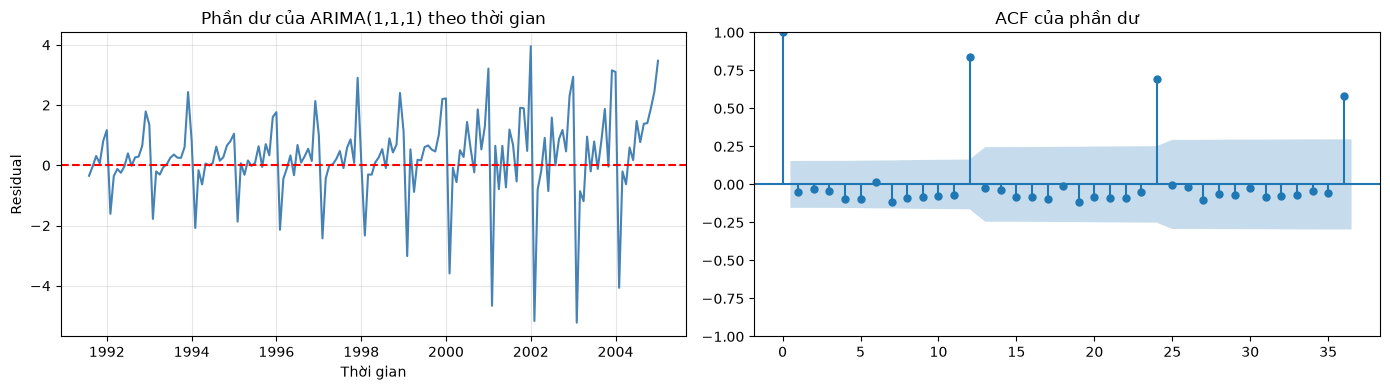

In [22]:
from statsmodels.graphics.tsaplots import plot_acf

res = models[(1, 1, 1)].resid.iloc[1:]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(res, color="steelblue")
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_title("Phần dư của ARIMA(1,1,1) theo thời gian")
ax[0].set_xlabel("Thời gian")
ax[0].set_ylabel("Residual")
ax[0].grid(True, alpha=0.3)
plot_acf(res, lags=36, ax=ax[1])
ax[1].set_title("ACF của phần dư")
plt.tight_layout()
plt.show()

In [23]:
from statsmodels.stats.diagnostic import acorr_ljungbox

rows = []
for o, m in models.items():
    r = m.resid.iloc[1:]
    lb = acorr_ljungbox(r, lags=[10, 12, 24], return_df=True)
    a = acf(r, nlags=24)
    rows.append({"Mô hình": f"ARIMA{o}",
                 "Mean": round(r.mean(), 3), "Std": round(r.std(), 3),
                 "ACF lag 1": round(a[1], 3), "ACF lag 12": round(a[12], 3),
                 "p LB lag 10": round(lb.lb_pvalue.loc[10], 4),
                 "p LB lag 12": round(lb.lb_pvalue.loc[12], 4),
                 "p LB lag 24": round(lb.lb_pvalue.loc[24], 4)})
pd.DataFrame(rows).set_index("Mô hình")

,Mean,Std,ACF lag 1,ACF lag 12,p LB lag 10,p LB lag 12,p LB lag 24
Mô hình,,,,,,,
"ARIMA(0, 1, 1)",0.207,1.455,0.071,0.854,0.0284,0.0,0.0
"ARIMA(1, 1, 1)",0.298,1.404,-0.048,0.840,0.4456,0.0,0.0
"ARIMA(2, 1, 1)",0.298,1.405,-0.045,0.840,0.4433,0.0,0.0


**Nhận xét:**
- **Mean:** Mean phần dư khoảng 0,2 đến 0,3, nhỏ so với độ lệch chuẩn (khoảng 1,4), nên xấp xỉ 0 và mô hình không lệch hệ thống nghiêm trọng.
- **Tự tương quan ngắn hạn:** ACF lag 1 gần 0 và Ljung-Box lag 10 của ARIMA(1,1,1) và (2,1,1) có p ≈ 0,44 (> 0,05), nên phần cấu trúc ngắn hạn đã được mô hình hóa tốt. ARIMA(0,1,1) có p = 0,028 (< 0,05), nghĩa là còn sót tự tương quan ngắn hạn, thêm một lý do để ưu tiên ARIMA(1,1,1).
- **Mùa vụ:** ACF của phần dư vẫn rất lớn tại lag 12 (≈ 0,84) và lag 24 (≈ 0,69); Ljung-Box lag 12 và 24 đều có p ≈ 0. Vậy phần dư **chưa phải nhiễu trắng**: ARIMA không có thành phần mùa vụ nên chưa nắm được chu kỳ 12 tháng.

## 5.4. Dự báo trên tập test và đánh giá
Dự báo `len(test)` bước tiếp theo từ cuối tập train, so với giá trị thực tế của test. Đánh giá bằng MAE, RMSE, MAPE.

In [24]:
def chi_so(thuc, du_bao):
    sai_so = thuc - du_bao
    mae = sai_so.abs().mean()
    rmse = np.sqrt((sai_so ** 2).mean())
    mape = (sai_so.abs() / thuc).mean() * 100
    return mae, rmse, mape

forecasts = {}
rows = []
for o, m in models.items():
    forecasts[o] = m.forecast(steps=len(test))
    mae, rmse, mape = chi_so(test, forecasts[o])
    rows.append({"Mô hình": f"ARIMA{o}", "AIC": round(m.aic, 2), "BIC": round(m.bic, 2),
                 "MAE": round(mae, 4), "RMSE": round(rmse, 4), "MAPE (%)": round(mape, 2)})

pd.DataFrame(rows).set_index("Mô hình")

,AIC,BIC,MAE,RMSE,MAPE (%)
Mô hình,,,,,
"ARIMA(0, 1, 1)",587.92,594.09,3.4598,4.1468,18.39
"ARIMA(1, 1, 1)",582.47,591.73,3.6667,4.6243,18.04
"ARIMA(2, 1, 1)",584.46,596.81,3.6702,4.6285,18.06


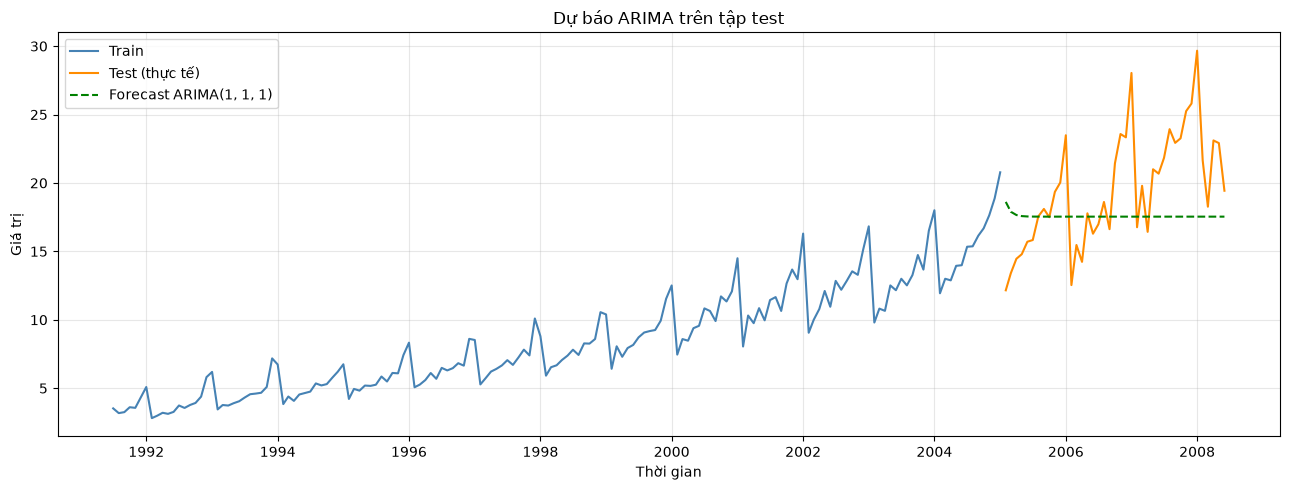

In [25]:
best = (1, 1, 1)

plt.figure(figsize=(13, 5))
plt.plot(train, label="Train", color="steelblue")
plt.plot(test, label="Test (thực tế)", color="darkorange")
plt.plot(forecasts[best], label=f"Forecast ARIMA{best}", color="green", linestyle="--")
plt.title("Dự báo ARIMA trên tập test")
plt.xlabel("Thời gian")
plt.ylabel("Giá trị")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
sai_so = (test - forecasts[best])
print("Top 5 tháng sai lệch lớn nhất:")
print(sai_so.abs().sort_values(ascending=False).head(5).round(2))
print()
print("Sai số tuyệt đối trung bình theo tháng:")
print(sai_so.abs().groupby(sai_so.index.month).mean().round(2))

Top 5 tháng sai lệch lớn nhất:
date
2008-01-01    12.13
2007-01-01    10.50
2007-12-01     8.27
2007-11-01     7.71
2005-02-01     6.46
dtype: float64

Sai số tuyệt đối trung bình theo tháng:
date
1     9.52
2     4.09
3     2.39
4     3.30
5     2.97
6     2.03
7     2.19
8     2.49
9     2.29
10    3.22
11    5.19
12    5.52
dtype: float64


**Nhận xét:**
- **Đồ thị:** đường dự báo của ARIMA gần như **nằm ngang** (khoảng 17,5 từ năm thứ hai trở đi), không lặp lại các đỉnh mùa vụ của chuỗi thực tế. Mô hình bám được **mức trung bình** nhưng không bám được **xu hướng tăng** và **chu kỳ 12 tháng**.
- **Sai lệch lớn nhất** tập trung vào các tháng 11, 12 và 1, đặc biệt tháng 1 (01/2008 lệch 12,13; 01/2007 lệch 10,50), là các đỉnh mùa vụ. Phần lớn dự báo thấp hơn thực tế, nên sai số lệch về một phía (trung bình thực tế cao hơn dự báo khoảng 1,9).
- **Các chỉ số:** MAE khoảng 3,5 đến 3,7, RMSE khoảng 4,1 đến 4,6, MAPE khoảng 18%. RMSE lớn hơn MAE vì RMSE bình phương sai số nên nhạy hơn với các sai lệch lớn ở đỉnh mùa vụ.
- **So sánh mô hình:** AIC/BIC chọn ARIMA(1,1,1), nhưng ARIMA(0,1,1) lại có MAE và RMSE thấp hơn trên test; MAPE của ba mô hình gần như bằng nhau. Chênh lệch này nhỏ, vì cả ba cùng không mô hình hóa được mùa vụ, nên không nên kết luận mô hình nào "thắng" rõ ràng.

### Nhận xét Bài 5

**Câu hỏi 1. Vì sao không được shuffle? Tập test dùng để làm gì?**
Chuỗi thời gian có phụ thuộc theo thứ tự: giá trị hiện tại phụ thuộc quá khứ. Nếu xáo trộn, mô hình sẽ được huấn luyện bằng các quan sát nằm **sau** thời điểm cần dự báo (rò rỉ thông tin từ tương lai) và phá vỡ cấu trúc tự tương quan, nên kết quả đánh giá quá lạc quan. Tập test (20% cuối) là dữ liệu mô hình chưa từng thấy, dùng để đo khả năng dự báo thật, đúng như khi dự báo tương lai.

**Câu hỏi 2. Ý nghĩa của p, d, q?**
- **p**: số bậc tự hồi quy (AR), giá trị hiện tại phụ thuộc p giá trị trước đó.
- **d**: số lần lấy sai phân để chuỗi dừng (ở đây d = 1, Bài 3).
- **q**: số bậc trung bình trượt (MA), giá trị hiện tại phụ thuộc q sai số dự báo trước đó.
Trong bài: d = 1 từ Bài 3, q = 1 từ ACF cắt sau lag 1, p thử 0, 1, 2 từ PACF (Bài 4).

**Câu hỏi 3. Mô hình có hội tụ không?**
Có. Cả ba mô hình ARIMA(0,1,1), (1,1,1), (2,1,1) đều hội tụ (`converged = True`) và không có cảnh báo lỗi khi fit.

**Câu hỏi 4. Residuals có phải nhiễu trắng không?**
**Chưa.** Mean phần dư khoảng 0,2 đến 0,3 (nhỏ so với độ lệch chuẩn khoảng 1,4) và ACF lag 1 gần 0, Ljung-Box lag 10 của ARIMA(1,1,1) có p ≈ 0,45. Nhưng ACF phần dư tại lag 12 ≈ 0,84 và Ljung-Box lag 12, 24 có p ≈ 0, tức còn tự tương quan mùa vụ rất mạnh.

**Câu hỏi 5. Nếu residuals còn tự tương quan thì điều chỉnh gì?**
Phần tự tương quan còn lại là ở chu kỳ 12 tháng, nên cần xử lý mùa vụ: lấy sai phân mùa (D = 1, s = 12) hoặc dùng SARIMA(p,1,q)(P,D,Q)12. Ở Bài 3, SARIMA cho MAPE khoảng 9%, so với khoảng 18% của ARIMA, cho thấy hướng điều chỉnh này đúng. Có thể thử thêm tham số p, q, nhưng không giải quyết được lag 12.

**Câu hỏi 6. Dự báo có bám xu hướng không?**
Chỉ bám **mức trung bình**. Đường dự báo gần như nằm ngang (khoảng 17,5), không tái hiện được xu hướng tăng và các đỉnh mùa vụ của chuỗi thực tế.

**Câu hỏi 7. Sai lệch lớn nhất xuất hiện ở đâu?**
Ở các **đỉnh mùa vụ**, tập trung vào tháng 11, 12 và 1, lớn nhất là tháng 1 (01/2008 lệch 12,13; 01/2007 lệch 10,50). Các tháng 6 đến 9 sai lệch nhỏ (khoảng 2 đến 2,5).

**Câu hỏi 8. Chỉ số nào nhạy với outlier nhất?**
**RMSE**, vì bình phương sai số nên các sai lệch lớn được khuếch đại. Ở đây RMSE (4,62) lớn hơn MAE (3,67) rõ rệt do các đỉnh tháng 1. MAE ít nhạy hơn; MAPE tính theo phần trăm nên nhạy khi giá trị thực nhỏ.

**Câu hỏi 9. RMSE lớn hay nhỏ cho biết điều gì?**
RMSE cùng đơn vị với dữ liệu, cho biết sai số dự báo "điển hình" (có trọng số ưu tiên sai lệch lớn). RMSE càng nhỏ thì dự báo càng sát thực tế. Với ARIMA(1,1,1), RMSE ≈ 4,62, tương đương khoảng 24% trung bình của tập test (19,5), là sai số khá lớn, phù hợp với việc mô hình chưa bắt được mùa vụ.

**Kết luận Bài 5:** ARIMA(1,1,1) tốt nhất theo AIC/BIC và phần dư ngắn hạn, nhưng ba mô hình dự báo gần như giống nhau (MAPE khoảng 18%) vì cùng thiếu thành phần mùa vụ. Cần chuyển sang SARIMA để cải thiện.